Calculating Error for N = 10 (Final vs Initial)...


/tmp/ipykernel_13923/1829725373.py:29: FutureWarning: In a future version of xarray decode_timedelta will default to False rather than None. To silence this warning, set decode_timedelta to True, False, or a 'CFTimedeltaCoder' instance.
  with xr.open_dataset(path) as ds:


Calculating Error for N = 15 (Final vs Initial)...
Calculating Error for N = 20 (Final vs Initial)...
Calculating Error for N = 30 (Final vs Initial)...
Calculating Error for N = 40 (Final vs Initial)...
Calculating Error for N = 60 (Final vs Initial)...
Calculating Error for N = 80 (Final vs Initial)...
Calculating Error for N = 100 (Final vs Initial)...


/tmp/ipykernel_13923/1829725373.py:29: FutureWarning: In a future version of xarray decode_timedelta will default to False rather than None. To silence this warning, set decode_timedelta to True, False, or a 'CFTimedeltaCoder' instance.
  with xr.open_dataset(path) as ds:
/tmp/ipykernel_13923/1829725373.py:29: FutureWarning: In a future version of xarray decode_timedelta will default to False rather than None. To silence this warning, set decode_timedelta to True, False, or a 'CFTimedeltaCoder' instance.
  with xr.open_dataset(path) as ds:
/tmp/ipykernel_13923/1829725373.py:29: FutureWarning: In a future version of xarray decode_timedelta will default to False rather than None. To silence this warning, set decode_timedelta to True, False, or a 'CFTimedeltaCoder' instance.
  with xr.open_dataset(path) as ds:
/tmp/ipykernel_13923/1829725373.py:29: FutureWarning: In a future version of xarray decode_timedelta will default to False rather than None. To silence this warning, set decode_time

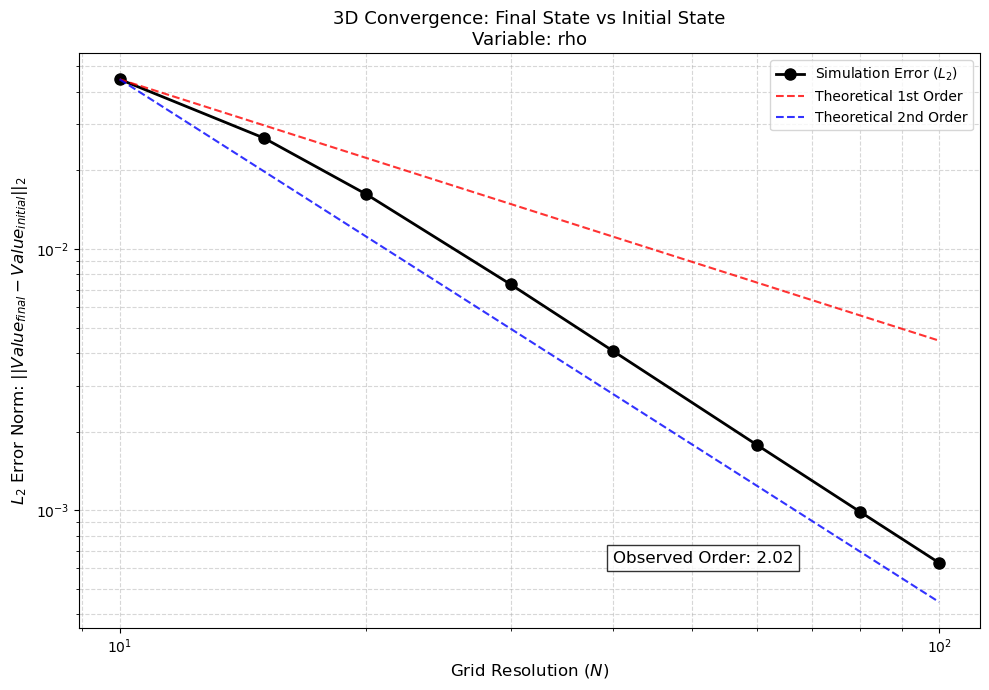

In [1]:
import os
import re
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

# --- Configuration ---
DATA_FOLDER = "/home/amir/Projects/Python/Atmpy/atmpy/output_data/traveling_vortex_3d/asymptotics/grid_convergence/"
FILE_PREFIX = "_traveling_vortex_3d"
# Now we can include 100 in the plot since we compare each file to its own start
RESOLUTIONS = [10, 15, 20, 30, 40, 60, 80, 100]
VARIABLE_NAME = "rho"

def get_file_path(res):
    filename = f"{FILE_PREFIX}_{res}_{res}_{res}.nc"
    for root, dirs, files in os.walk(DATA_FOLDER):
        if filename in files:
            return os.path.join(root, filename)
    return None

errors = []
actual_n = []

# 1. Calculate Errors
for n in RESOLUTIONS:
    path = get_file_path(n)
    if path:
        print(f"Calculating Error for N = {n} (Final vs Initial)...")
        with xr.open_dataset(path) as ds:
            # Get the variable at the FIRST time step (Initial Condition)
            initial_state = ds[VARIABLE_NAME].isel(time=0).values

            # Get the variable at the LAST time step (Final State)
            final_state = ds[VARIABLE_NAME].isel(time=-1).values

            # Error = Final - Initial
            diff = final_state - initial_state

            # L2 Norm: sqrt(mean(difference squared))
            l2_err = np.sqrt(np.mean(diff**2))

            errors.append(l2_err)
            actual_n.append(n)

# 2. Plotting
plt.figure(figsize=(10, 7))

# Plot actual simulation data
plt.loglog(actual_n, errors, 'ko-', markersize=8, linewidth=2, label='Simulation Error ($L_2$)')

# --- Add Reference Order Lines ---
# Anchoring to the first point
n_array = np.array(actual_n)
first_err = errors[0]
first_n = actual_n[0]

line_1st = first_err * (first_n / n_array)**1
line_2nd = first_err * (first_n / n_array)**2

plt.loglog(n_array, line_1st, 'r--', alpha=0.8, label='Theoretical 1st Order')
plt.loglog(n_array, line_2nd, 'b--', alpha=0.8, label='Theoretical 2nd Order')

# Calculate Observed Order (Slope)
# We use the mid-to-high resolution range for a more accurate slope
slope, _ = np.polyfit(np.log(actual_n[2:]), np.log(errors[2:]), 1)
observed_order = abs(slope)

# --- Formatting ---
plt.title(f"3D Convergence: Final State vs Initial State\nVariable: {VARIABLE_NAME}", fontsize=13)
plt.xlabel("Grid Resolution ($N$)", fontsize=12)
plt.ylabel("$L_2$ Error Norm: $||Value_{final} - Value_{initial}||_2$", fontsize=12)
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend()

plt.text(actual_n[len(actual_n)//2], errors[-1], f"Observed Order: {observed_order:.2f}",
         fontsize=12, bbox=dict(facecolor='white', alpha=0.8))

plt.tight_layout()
plt.show()